# This tends to solve task1, 2

This part of casework focuses on the demand aspect from the market, with objects of interests:

- ZIP3 market spot which can be categorized into 3 types and its demand each day

In [1]:
import pandas as pd 
import os 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

In [2]:
data_path = "data"

file_names = ['demand_seasonalities.csv', 'zip3_pmf.csv', 'zip3_coordinates.csv']
var_names = ['seasonality', 'pmf', 'location']

seasonality, pmf, location = [pd.read_csv(f"{data_path}/{file}") 
                             for file in file_names]

df = pd.merge(pmf, location, on='ZIP3')
print("locationwise data: ", df.head())
print("\nseasonality data: ", seasonality.info())

locationwise data:     ZIP3       PMF        Lat        Lon
0    10  0.002022  42.221598 -72.573558
1    11  0.001160  42.105773 -72.583739
2    12  0.000565  42.396595 -73.237576
3    13  0.000148  42.578956 -72.540044
4    14  0.000743  42.566233 -71.696724
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Week of Year  52 non-null     int64  
 1   Proportion    52 non-null     object 
 2   Unnamed: 2    0 non-null      float64
 3   Day of Week   7 non-null      float64
 4   Proportion.1  7 non-null      object 
dtypes: float64(2), int64(1), object(2)
memory usage: 2.2+ KB

seasonality data:  None


In [3]:
# preprocess the seasonality columns

seasonality.drop(columns=['Unnamed: 2'], inplace=True)
seasonality.columns = ['Wk', 'P_wk', 'Day', 'P_day']

# Convert percentage strings to floats
seasonality['P_wk'] = seasonality['P_wk'].str.rstrip('%').astype('float') / 100.0 # these used to be strings
seasonality['P_day'] = seasonality['P_day'].str.rstrip('%').astype('float') / 100.0

print("new info:", seasonality.info())

print("number of locations:", len(pmf['ZIP3'].unique()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Wk      52 non-null     int64  
 1   P_wk    52 non-null     float64
 2   Day     7 non-null      float64
 3   P_day   7 non-null      float64
dtypes: float64(3), int64(1)
memory usage: 1.8 KB
new info: None
number of locations: 852


since there are so many sources of randomness, here we use simulation to draw inference on behaviors in planning horizon

In [4]:
# simulation function

def simulate(n_sim = 1000, seed = 42):

    n_weeks = seasonality['P_wk'].dropna().shape[0]  
    n_days = seasonality['P_day'].dropna().shape[0]   
    n_locations = pmf['ZIP3'].nunique()              
    
    results = np.zeros((n_sim, n_weeks * n_days, n_locations)) # (n_sim, 364, 852)
    
    for i in range(n_sim):
 
        rng = np.random.default_rng(seed + i) # different seed for each simulation

        # Convert pandas Series to numpy arrays and filter out NaN values
        p_wk_values = seasonality['P_wk'].dropna().values
        p_day_values = seasonality['P_day'].dropna().values
        
        seasonality_wk = rng.normal(loc = p_wk_values, scale = p_wk_values*0.2, size = len(p_wk_values))
        seasonality_day = rng.normal(loc = p_day_values, scale = p_day_values*0.15, size = len(p_day_values)) # both iD array (n,)

        pmf_sim = rng.normal(loc = pmf['PMF'].values, scale = pmf['PMF'].values*0.15, size = len(pmf))

        market_share = rng.triangular(left=0.186, mode=0.236, right=0.286)
        overall_demand_perc = rng.triangular(left=1.04, mode=1.075, right=1.12)

        overall_demand = 2000000 * overall_demand_perc

        seasonality_matrix = np.outer(seasonality_wk, seasonality_day) # (52, 7)
        demand_array = seasonality_matrix.flatten() * overall_demand # (364,)

        zip3_demand = np.outer(demand_array, pmf_sim) * market_share # (364, n_zip3=852)

        results[i, :, :] = zip3_demand 
    return results # (n_sim, 364, 852)

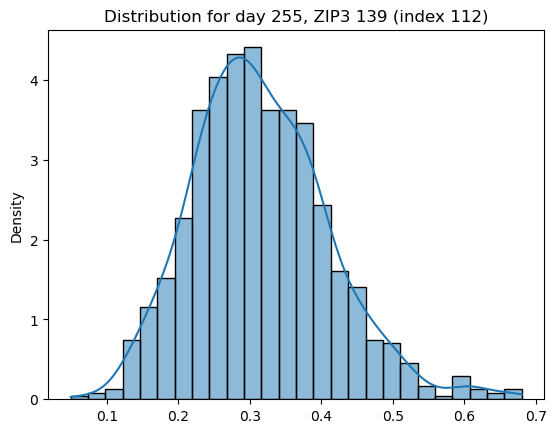

Skewness: 0.5576070625665931
Kurtosis: 0.6975507028136625
ShapiroResult(statistic=0.9825226072415097, pvalue=1.3965212568009173e-09)
NormaltestResult(statistic=58.68653553901414, pvalue=1.8045990595099664e-13)


In [5]:
# call

n_sim = 1000
sim_results = simulate(n_sim, seed=42)

# check the shape of distribution
index = (255, 112) # within (364, 852)

# Get the actual ZIP3 value 
zip3_value = pmf.iloc[index[1]]['ZIP3']

single_result = sim_results[:, index[0], index[1]]
# single_result = np.zeros(n_sim)

# for i in range(n_sim):
#     single_result[i] = sim_results[i, index[0], index[1]]
plt.figure()
sns.histplot(single_result, kde=True, stat='density')
plt.title(f"Distribution for day {index[0]}, ZIP3 {zip3_value:g} (index {index[1]})")
plt.show()

# statistics
skew = st.skew(single_result)
kurt = st.kurtosis(single_result)  

print("Skewness:", skew)
print("Kurtosis:", kurt)

# normality
print(st.shapiro(single_result))
print(st.normaltest(single_result))

this does not pass the normality test but look bell like due to large number of simulations

so we still use t-interval to estimate CIs

In [6]:
print(sim_results.shape)

(1000, 364, 852)


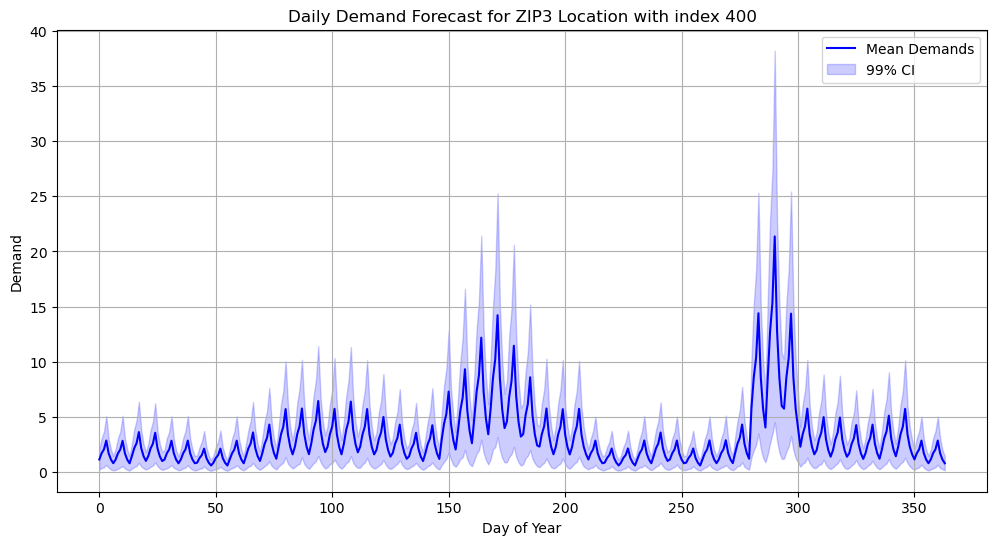

In [8]:
mean_est = sim_results.mean(axis=0)
std_est = sim_results.std(axis=0, ddof=1)

alphas = [0.32, 0.05, 0.01]
confidence_interval =  {}

for alpha in alphas: 
    z = st.norm.ppf(1 - alpha/2)
    ci_lower = mean_est - z*std_est
    ci_upper = mean_est + z*std_est

    confidence_interval[f"CI_{int((1 - alpha) * 100)}"] = (ci_lower, ci_upper)

# in 99% CI case
# visualize the daily demand for a selectd day in a selected location
ZIP3_index = 400
confidence = 99 # within alpha

plt.figure(figsize = (12, 6))
plt.plot(range(364), mean_est[:, ZIP3_index], 'b-', label = 'Mean Demands' )


ci_L = confidence_interval[f'CI_{confidence}'][0][:, ZIP3_index]
ci_U = confidence_interval[f'CI_{confidence}'][1][:, ZIP3_index]

plt.fill_between(
    range(364),
    ci_L,
    ci_U,
    color='b',
    alpha=0.2,
    label=f'{confidence}% CI'
)
plt.title(f'Daily Demand Forecast for ZIP3 Location with index {ZIP3_index}')
plt.xlabel('Day of Year')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.show()

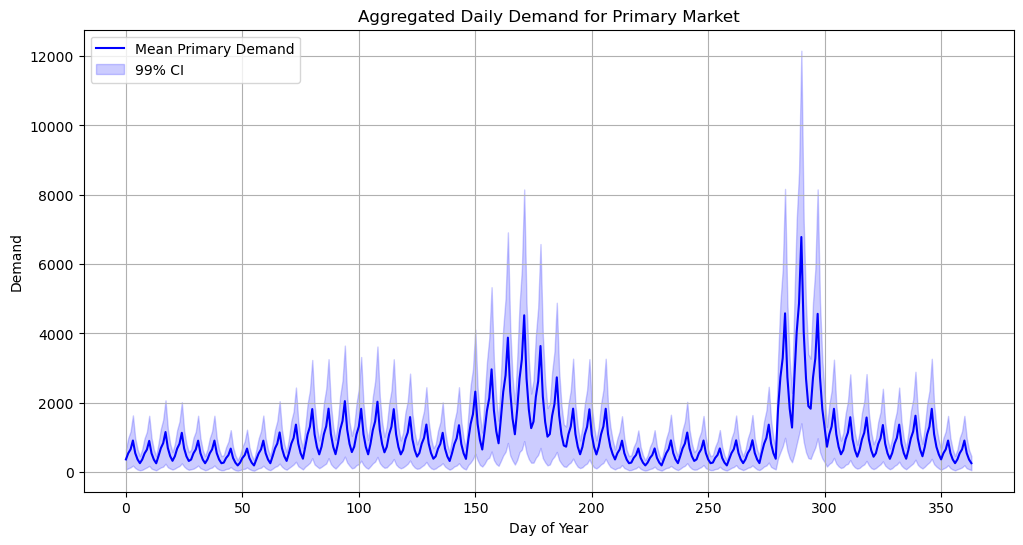

In [9]:
# aggregate market type CI

market = pd.read_csv("./data/zip3_market.csv")

category = 'Primary' # change within P, S, T

zip_list = market.loc[(market["Market"] == category), "ZIP3"]

# create a ZIP3 indexing object, the ZIP3 value ~ index is created from pmf dataset
mapping = pd.DataFrame({
    'ZIP3': pmf['ZIP3'].values,
    'indexing': range(len(pmf))
})

# still go with same alpha value as for daily demand 
days = mean_est.shape[0]
mean_agg = np.zeros(days)
upper_agg = np.zeros(days)
lower_agg = np.zeros(days)

for zip_code in zip_list:
    # Check if ZIP code exists in mapping before accessing
    zip_matches = mapping.loc[mapping['ZIP3'] == zip_code, 'indexing']
    if not zip_matches.empty:
        zip_index = zip_matches.iloc[0]
        mean_agg += mean_est[:, zip_index]
        upper_agg += confidence_interval[f"CI_{confidence}"][1][:, zip_index]
        lower_agg += confidence_interval[f"CI_{confidence}"][0][:, zip_index]
    else:
        print(f"Warning: ZIP3 {zip_code} not found in PMF data")

# visualization
plt.figure(figsize=(12, 6))
plt.plot(range(days), mean_agg, 'b-', label=f'Mean {category} Demand')
plt.fill_between(range(days), lower_agg, upper_agg, color='b', alpha=0.2, 
                 label=f'{confidence}% CI')
plt.title(f'Aggregated Daily Demand for {category} Market')
plt.xlabel('Day of Year')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
# Get 99% confidence intervals
ci_99_lower = confidence_interval['CI_99'][0]  # (364, 852)
ci_99_upper = confidence_interval['CI_99'][1]  # (364, 852)

n_days, n_locations = mean_est.shape

# Create flattened data structure
data_rows = []

for day in range(n_days):
    for loc_idx in range(n_locations):
        zip3_code = pmf.iloc[loc_idx]['ZIP3'].astype(int)

        row = {
            'Day': day + 1,  # 1-indexed for readability
            'ZIP3': zip3_code,
            'Mean_Demand': round(mean_est[day, loc_idx], 2),
            'CI_99_Min': round(ci_99_lower[day, loc_idx], 2),
            'CI_99_Max': round(ci_99_upper[day, loc_idx], 2),
            'Range_99': round(ci_99_upper[day, loc_idx] - ci_99_lower[day, loc_idx], 2)
        }
        data_rows.append(row)

# Create DataFrame and export
df_simulation = pd.DataFrame(data_rows)
df_simulation.to_csv('./data/simulation_results.csv', index=False)

print("Simulation results exported to simulation_results.csv")
print(f"Data shape: {df_simulation.shape}")
print("Sample data:")
print(df_simulation.head(10))

Simulation results exported to simulation_results.csv
Data shape: (310128, 6)
Sample data:
   Day  ZIP3  Mean_Demand  CI_99_Min  CI_99_Max  Range_99
0    1    10         1.04       0.18       1.90      1.73
1    1    11         0.59       0.13       1.06      0.94
2    1    12         0.29       0.06       0.52      0.47
3    1    13         0.08       0.01       0.14      0.13
4    1    14         0.39       0.07       0.70      0.63
5    1    15         0.74       0.14       1.35      1.21
6    1    16         0.41       0.09       0.73      0.65
7    1    17         0.61       0.12       1.10      0.99
8    1    18         1.43       0.31       2.56      2.25
9    1    19         1.16       0.22       2.09      1.87


The demands seems too small assuming units is for unit product. However, rough estimation via manual multiplication from overall demand to decomposite through time, pmf this makes sense